<a href="https://colab.research.google.com/github/SamsGibsP/TI4006_GA/blob/main/P11_Hands_on_GA_TSP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on Pertemuan 11 — Genetic Algorithm untuk TSP
**TI 4006 Algoritma Optimisasi dan Metaheuristik**

Hands-on ini menggunakan kode **TSP – Genetic Algorithm** yang telah tersedia dan mengembangkannya secara bertahap.

| Tahap | Isi |
|---|---|
| 1 | Penelusuran manual GA berukuran kecil (10 simpul, 2 generasi) |
| 2 | Eksekusi GA 50 pelanggan (kode asli) |
| 3 | Pengukuran waktu komputasi (profiling) |
| 4 | Riwayat konvergensi, elitisme, fungsi eksperimen |
| 5 | Operator lain: order crossover (OX) dan inversion mutation |
| 6 | Rancangan eksperimen: seed, beberapa eksekusi, anggaran yang setara |
| 7 | GA + 2-opt (memetic algorithm) |
| – | Tantangan kelas: satu modifikasi sendiri |
| 8 | Instance TSPLIB (persiapan Tugas GA) |

Kode asli tidak diubah. Setiap perubahan ditulis sebagai fungsi baru dan ditandai `# BARU`.
Latihan ditandai dengan ✏️.

## Tahap 1 — Penelusuran GA berukuran kecil

Sel berikut merupakan kode asli versi kecil (10 simpul, populasi 10, setiap langkah dicetak). Seed ditetapkan agar seluruh mahasiswa memperoleh keluaran yang sama.

Pseudocode yang diimplementasikan oleh kode ini:
```
1. P <- populasi awal (permutasi simpul 1..n-1; simpul 0 = depot, tetap di awal dan akhir)
2. evaluasi: jarak total, fitness = 1 / jarak total
3. ULANGI untuk setiap generasi :
3.1   ULANGI ukuran_populasi/2 kali :
         induk1, induk2 <- seleksi turnamen
         dengan peluang crossover_rate : anak1, anak2 <- position-based crossover
         dengan peluang mutation_rate  : swap mutation pada tiap anak
3.2   P <- semua anak                       (generational, tanpa elitisme)
3.3   evaluasi P, perbarui solusi terbaik sepanjang run
```

In [ ]:
import random as rd
import numpy as np
rd.seed(11); np.random.seed(11)    # BARU: seed agar keluaran seragam di seluruh kelas

In [ ]:
# Genetic Algoritthm untuk TSP

import numpy as np
import random as rd
import matplotlib.pyplot as plt
import time

"""
# Data
jarak = [
  [ 0,  9, 14, 10, 20, 11, 15, 17,  8,  3],
  [ 8,  0, 17,  4, 13,  8,  5,  1,  5, 14],
  [ 9, 17,  0, 16, 10, 14,  3,  8,  4,  5],
  [ 9, 19,  1,  0,  8,  4, 19,  6, 14, 12],
  [10,  5, 19, 10,  0, 15, 12, 19, 17,  7],
  [16, 19,  1, 17,  2,  0,  2,  3, 18, 10],
  [13, 17,  3, 18,  8, 18,  0,  4, 17,  5],
  [ 8,  6,  4, 16, 11,  6, 17,  0,  4, 11],
  [17, 15, 20,  2,  2,  7, 12,  9,  0, 17],
  [17,  2,  6,  8, 20, 10,  6, 15,  4,  0]]
jumlah_simpul = len(jarak)
daftar_simpul = list(range(jumlah_simpul))
"""

jumlah_simpul = 10
xsimpul = jumlah_simpul**2 - jumlah_simpul
daftar = list(range(1,xsimpul+1))
a = rd.sample(daftar,xsimpul)
print(a)
jarak = np.zeros((jumlah_simpul,jumlah_simpul))
k = 0
for i in range(jumlah_simpul):
    for j in range(jumlah_simpul):
        if i != j:
            jarak[i][j] = a[k]
            k += 1
daftar_simpul = list(range(jumlah_simpul))

print(daftar_simpul)

# Parameter-parameter algoritma:
ukuran_populasi = 100
crossover_rate = 0.7
mutation_rate = 0.1
max_generation = 3

# parameter-paramater masalah:
panjang_kromosom = jumlah_simpul - 1
ukuran_turnamen = 5 # Define ukuran_turnamen

# pembangkitan populasi awal
def pembangkitan_populasi_awal(ukuran_populasi, jumlah_titik, panjang_kromosom):
    populasi = []
    for _ in range(ukuran_populasi):
        simpul_tersedia = daftar_simpul[1:]
        kromosom = rd.sample(simpul_tersedia, jumlah_titik - 1)
        populasi.append(kromosom)

    return populasi

# proses dekoding, penentuan nilai fungsi tujuan, dan nilai fitnes
def evalusi_populasi(ukuran_populasi, kromosom, panjang_kromosom, jarak):

    # Bangun solusi dari kromosom
    solusi = [[0] * (panjang_kromosom + 2) for _ in range(ukuran_populasi)]
    total_jarak = [0.0] * ukuran_populasi
    fitness = [0.0] * ukuran_populasi
    for p in range(ukuran_populasi):
        solusi[p] = [0] + list(map(int, kromosom[p])) + [0] # Tambah titik nol, syarat TSP

    # Hitung total jarak
    for p in range(ukuran_populasi):
        total_jarak[p] = sum(jarak[solusi[p][j]][solusi[p][j + 1]] for j in range(len(solusi[p]) - 1))

    # Hitung fitness
    for p in range(ukuran_populasi):
        # fitness = 1 / jarak total
        fitness[p] = 1 / total_jarak[p] if total_jarak[p] != 0 else 0

    # Cari solusi terbaik pada popuplasi
    p_best = np.argmax(fitness) # maksimisasi fitness (minimisasi jarak total)
    best_solusi = solusi[p_best]
    best_fitness = fitness[p_best]

    return solusi, total_jarak, fitness, p_best


# Seleksi Turnamem
def seleksi_turnamen(ukuran_populasi, x_populasi, nilai_fitness, ukuran_turnamen): # Added ukuran_turnamen as argument
    # membuat list yang berisi indeks calon induk sebanyak ukuran turnamen
    indeks_parent_terpilih = rd.sample(range(ukuran_populasi), ukuran_turnamen)
    kandidat = [(x_populasi[i], nilai_fitness[i]) for i in indeks_parent_terpilih]

    for i in range(len(indeks_parent_terpilih)):
        print(f'calon: {kandidat[i][0]} nilai fitnes = {kandidat[i][1]:.4f}')

    kandidat.sort(key=lambda x: x[1], reverse=True) # urutkan berdasarkan fitness (kasus maksimisasi)
    parent = kandidat[0][0] # pilih pada urutan pertama

    return parent

def position_based_crossover(induk1, induk2): # Removed unnecessary arguments
    panjang_kromosom = len(induk1)
    anak1 = [None] * panjang_kromosom
    anak2 = [None] * panjang_kromosom
    jumlah_posisi_yang_dipilih = np.random.randint(1, panjang_kromosom) # Jumlah yang akan ditukar Random => Bisa saja posisi yang dipilih tidak ada sehingga tidak terjadi pertukaran, lanjut tanpa mutasi
    posisi_yang_dipilih = np.random.choice(panjang_kromosom, jumlah_posisi_yang_dipilih, replace=False) # Posisi yang akan ditukar
    posisi_yang_dipilih.sort()

    for posisi in posisi_yang_dipilih:
        anak1[posisi] = induk1[posisi]
    sisa_gen_induk2 = [gen for gen in induk2 if gen not in [anak1[pos] for pos in posisi_yang_dipilih]]
    indeks_sisa_gen = 0
    for i in range(panjang_kromosom):
        if anak1[i] is None:
            anak1[i] = sisa_gen_induk2[indeks_sisa_gen]
            indeks_sisa_gen += 1

    for posisi in posisi_yang_dipilih:
        anak2[posisi] = induk2[posisi]
    sisa_gen_induk1 = [gen for gen in induk1 if gen not in [anak2[pos] for pos in posisi_yang_dipilih]]
    indeks_sisa_gen = 0
    for i in range(panjang_kromosom):
        if anak2[i] is None:
            anak2[i] = sisa_gen_induk1[indeks_sisa_gen]
            indeks_sisa_gen += 1



    return anak1, anak2

def swap_mutation(kromosom): # Removed unnecessary arguments, mana yang mau ditukar
    panjang_kromosom = len(kromosom)
    idx1 = rd.randint(0,panjang_kromosom-1)
    idx2 = rd.randint(0,panjang_kromosom-1)
    while idx2 == idx1:
        idx2 = rd.randint(0,panjang_kromosom-1)
    kromosom[idx1], kromosom[idx2] = kromosom[idx2], kromosom[idx1]
    return kromosom

# fungsi reproduksi
def reproduksi(ukuran_populasi, populasi, nilai_fitness, crossover_rate, mutation_rate, ukuran_turnamen): # Added ukuran_turnamen as argument

    populasi_lama = populasi.copy()
    populasi_baru  = []

    for _ in range(ukuran_populasi // 2):
        # Seleksi turnamen
        print(f'seleksi')

        induk1 = seleksi_turnamen(ukuran_populasi, populasi_lama, nilai_fitness, ukuran_turnamen) # Added comma and ukuran_turnamen
        print(f'Induk 1 {induk1}')

        induk2 = seleksi_turnamen(ukuran_populasi, populasi_lama, nilai_fitness, ukuran_turnamen) # Added ukuran_turnamen
        print(f'Induk 2 {induk2}')

        # Persilangan
        print(f'persilangan')
        if np.random.random() < crossover_rate:
            anak1, anak2 = position_based_crossover(induk1, induk2)
        else:
            anak1, anak2 = induk1.copy(), induk2.copy()
        print(f'anak 1 {anak1}')
        print(f'anak 2 {anak2}')

        # Mutasi
        print(f'mutasi')
        if np.random.random() < mutation_rate:
            anak1 = swap_mutation(anak1) # lakukan mutasi
        print(f'anak 1 {anak1}')
        if np.random.random() < mutation_rate:
            anak2 = swap_mutation(anak2) # lakukan mutasi
        print(f'anak 2 {anak2}')

        # Pembaruan populasi
        populasi_baru.append(anak1)
        populasi_baru.append(anak2)

    return populasi_baru

def genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate, mutation_rate, max_generation, ukuran_turnamen): # Added ukuran_turnamen as argument
    gen = 0

    populasi = pembangkitan_populasi_awal(ukuran_populasi, jumlah_simpul, panjang_kromosom)

    print('Populasi awal')
    for i in range(len(populasi)):
        populasi[i] = list(map(int, populasi[i]))
        print(populasi[i])
    print()

    # Evaluasi populasi
    solusi, total_jarak, fitness, p_best = evalusi_populasi(ukuran_populasi, populasi, panjang_kromosom, jarak)

    # Inisialisasi best solution
    best_idx = np.argmax(fitness)
    best_solusi = solusi[best_idx]
    best_fitness = fitness[best_idx]

    while gen <= max_generation:
        gen += 1
        # Reproduksi (seleksi, persilangan, mutasi)
        populasi = reproduksi(ukuran_populasi, populasi, fitness, crossover_rate, mutation_rate, ukuran_turnamen)

        print(f'Generasi: {gen}')
        print('Populasi:')
        for i in range(len(populasi)):
            populasi[i] = list(map(int, populasi[i]))
            print(populasi[i])
        print()


        print(np.array(populasi))
        print()

        # Evaluasi solusi (dekoding, nilai fungsi tujuan, nilai fitness)
        solusi, total_jarak, fitness, p_best = evalusi_populasi(ukuran_populasi, populasi, panjang_kromosom, jarak)

        # Pembaruan solusi terabaik sepanjang generasi
        idx = np.argmax(fitness)
        if fitness[idx] > best_fitness:
            best_solusi = solusi[idx]
            best_fitness = fitness[idx]

        # Cetak kemajuan solusi terbaik tiap 100 generasi
        if gen % 100 == 0:
            print(f'generasi = {gen+1}, jarak total = {1/best_fitness:.4f}, fitnes = {best_fitness:.6f}')
    return best_solusi, best_fitness

# Kode utama
saat_mulai = time.time()
best_solusi, best_fitness =  genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate, mutation_rate, max_generation, ukuran_turnamen) # Added ukuran_turnamen
waktu_komputasi = time.time() - saat_mulai

print('\nSolusi terbaik:')
best_solusi = [int(i) for i in best_solusi]
print(f'{best_solusi}')
print(f'jarak total = {1/best_fitness:.4f}')
print(f'waktu komputasi = {waktu_komputasi:.2f} detik')

[69, 52, 90, 33, 29, 75, 26, 55, 8, 25, 15, 37, 22, 76, 31, 66, 19, 80, 34, 39, 53, 2, 43, 54, 84, 4, 74, 88, 5, 77, 50, 89, 85, 35, 82, 11, 32, 40, 57, 18, 1, 86, 58, 78, 6, 7, 60, 73, 64, 45, 81, 48, 10, 16, 44, 65, 56, 46, 68, 3, 27, 67, 21, 24, 83, 79, 51, 87, 36, 28, 62, 17, 20, 41, 49, 42, 14, 47, 12, 59, 30, 38, 23, 13, 71, 63, 61, 9, 70, 72]
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Populasi awal
[4, 8, 3, 2, 5, 7, 1, 6, 9]
[5, 3, 2, 9, 6, 4, 1, 7, 8]
[9, 2, 8, 4, 1, 7, 6, 5, 3]
[4, 8, 7, 1, 3, 9, 6, 5, 2]
[1, 3, 5, 7, 4, 9, 8, 2, 6]
[5, 4, 1, 3, 8, 6, 2, 7, 9]
[3, 7, 8, 1, 6, 5, 2, 4, 9]
[3, 5, 6, 7, 4, 8, 9, 2, 1]
[3, 1, 9, 6, 4, 5, 8, 7, 2]
[2, 5, 4, 6, 9, 1, 7, 3, 8]
[9, 6, 7, 8, 2, 4, 3, 5, 1]
[2, 1, 9, 4, 6, 7, 8, 5, 3]
[6, 8, 9, 5, 4, 3, 2, 1, 7]
[8, 9, 6, 1, 7, 4, 5, 3, 2]
[3, 5, 1, 6, 8, 2, 4, 7, 9]
[5, 3, 7, 2, 1, 9, 4, 8, 6]
[1, 3, 2, 7, 8, 6, 5, 9, 4]
[1, 5, 9, 2, 4, 3, 6, 8, 7]
[8, 7, 1, 3, 9, 2, 6, 5, 4]
[6, 4, 1, 3, 2, 8, 7, 5, 9]
[8, 5, 1, 3, 6, 2, 4, 7, 9]
[3, 9, 7, 5, 8,

✏️ **Latihan 1.1** — Pilih satu pasangan induk yang mengalami persilangan pada keluaran di atas. Tentukan posisi yang diwariskan induk 1 kepada anak 1, kemudian periksa bahwa sisa gen diisi **mengikuti urutan induk 2**.

✏️ **Latihan 1.2** — Anak 1 dapat identik dengan induk 1. Jelaskan penyebabnya dan tentukan peluangnya untuk satu pasangan induk.

✏️ **Latihan 1.3** — Fitness = 1 / jarak total. Pada seleksi turnamen, apakah besaran nilai fitness berpengaruh, atau hanya urutannya?

## Tahap 2 — GA 50 pelanggan (kode asli)

Sel dijalankan tanpa perubahan. Catat **jarak total** dan **waktu komputasi**, kemudian bandingkan dengan hasil mahasiswa lain.

[[40 15 42 ... 49 19 38]
 [19  8 37 ...  3 46  2]
 [ 8 34 29 ... 27 37 18]
 ...
 [31 17 38 ... 12 45 23]
 [29 39 42 ... 14 47 45]
 [22  7 13 ... 34 33  9]]

generasi = 1, jarak total = 2150.8200, fitnes = 0.000465
generasi = 101, jarak total = 1115.0665, fitnes = 0.000897
generasi = 201, jarak total = 994.3204, fitnes = 0.001006
generasi = 301, jarak total = 915.4141, fitnes = 0.001092
generasi = 401, jarak total = 881.7398, fitnes = 0.001134
generasi = 501, jarak total = 843.9916, fitnes = 0.001185
generasi = 601, jarak total = 843.9916, fitnes = 0.001185
generasi = 701, jarak total = 843.9916, fitnes = 0.001185
generasi = 801, jarak total = 843.9916, fitnes = 0.001185
generasi = 901, jarak total = 843.9916, fitnes = 0.001185
generasi = 1001, jarak total = 843.9916, fitnes = 0.001185

Solusi terbaik:
[0, 5, 41, 34, 28, 42, 4, 13, 12, 37, 8, 15, 38, 44, 22, 29, 25, 36, 45, 27, 32, 48, 21, 39, 14, 40, 33, 19, 23, 16, 3, 1, 18, 10, 30, 24, 49, 46, 43, 9, 26, 20, 17, 35, 50, 11, 47, 2, 6,

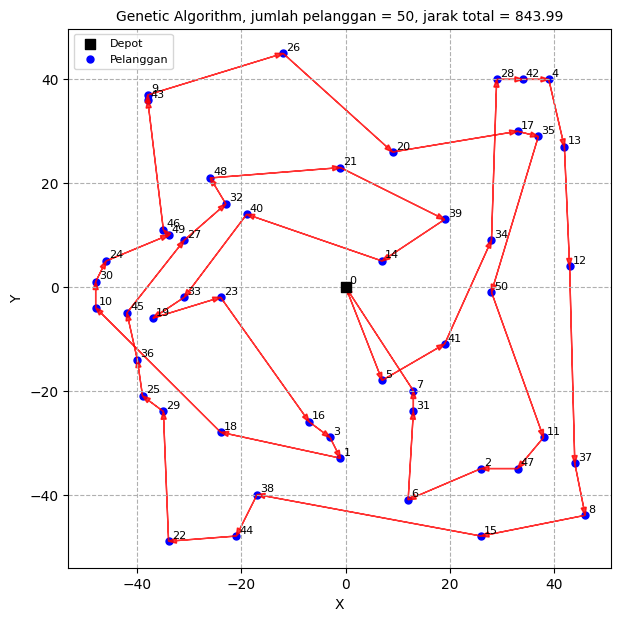

In [ ]:
# Genetic Algoritthm untuk TSP

import numpy as np
import random as rd
import matplotlib.pyplot as plt
import time

# Data
np.random.seed(1707) # seed agar data random yang dibangkitkan selalu tetap
jumlah_pelanggan = 50  # dapat diatur jumlah pelanggan
jumlah_simpul = jumlah_pelanggan + 1
# simpul depot pada koordinat (0, 0) dan koordinat simpul pelanggan random (-50, 50)
koord_x = [0] + [np.random.randint(-50, 50) for _ in range(jumlah_simpul - 1)]
koord_y = [0] + [np.random.randint(-50, 50) for _ in range(jumlah_simpul - 1)]

jarak = np.zeros((jumlah_simpul, jumlah_simpul))
# list simpul mulai dari depot (simpul 0) s/d jumlah simpul
daftar_simpul = list(range(jumlah_simpul))
# Hitung jarak Euclides
for i in daftar_simpul:
    for j in daftar_simpul:
        if i != j:
            jarak[i][j] = \
            np.sqrt((koord_x[i] - koord_x[j])**2 + (koord_y[i] - koord_y[j])**2)
np.random.seed(None) # nonaktifkan seed dalam randomisasi


# Parameter-parameter algoritma:
ukuran_populasi = 200
crossover_rate = 0.7
mutation_rate = 0.05
max_generation = 1000

# parameter-paramater masalah:
panjang_kromosom = jumlah_simpul - 1
ukuran_turnamen = int(0.1*ukuran_populasi) # Define ukuran_turnamen

# pembangkitan populasi awal
def pembangkitan_populasi_awal(ukuran_populasi, jumlah_titik, panjang_kromosom):
    populasi = []
    for _ in range(ukuran_populasi):
        simpul_tersedia = daftar_simpul[1:]
        kromosom = rd.sample(simpul_tersedia, jumlah_titik - 1)
        populasi.append(kromosom)

    print(np.array(populasi))
    print()

    return populasi

# proses dekoding, penentuan nilai fungsi tujuan, dan nilai fitnes
def evalusi_populasi(ukuran_populasi, kromosom, panjang_kromosom, jarak):

    # Bangun solusi dari kromosom
    solusi = [[0] * (panjang_kromosom + 2) for _ in range(ukuran_populasi)]
    total_jarak = [0.0] * ukuran_populasi
    fitness = [0.0] * ukuran_populasi
    for p in range(ukuran_populasi):
        solusi[p] = [0] + list(map(int, kromosom[p])) + [0]

    # Hitung total jarak
    for p in range(ukuran_populasi):
        total_jarak[p] = sum(jarak[solusi[p][j]][solusi[p][j + 1]] for j in range(len(solusi[p]) - 1))

    # Hitung fitness
    for p in range(ukuran_populasi):
        # fitness = 1 / jarak total
        fitness[p] = 1 / total_jarak[p] if total_jarak[p] != 0 else 0

    # Cari solusi terbaik pada popuplasi
    p_best = np.argmax(fitness) # maksimisasi fitness (minimisasi jarak total)
    best_solusi = solusi[p_best]
    best_fitness = fitness[p_best]

    return solusi, total_jarak, fitness, p_best


# Seleksi Turnamem
def seleksi_turnamen(ukuran_populasi, x_populasi, nilai_fitness, ukuran_turnamen): # Added ukuran_turnamen as argument
    # membuat list yang berisi indeks calon induk sebanyak ukuran turnamen
    indeks_parent_terpilih = rd.sample(range(ukuran_populasi), ukuran_turnamen)
    kandidat = [(x_populasi[i], nilai_fitness[i]) for i in indeks_parent_terpilih]
    kandidat.sort(key=lambda x: x[1], reverse=True) # urutkan berdasarkan fitness (kasus maksimisasi)
    parent = kandidat[0][0] # pilih pada urutan pertama
    return parent

def position_based_crossover(induk1, induk2): # Removed unnecessary arguments
    panjang_kromosom = len(induk1)
    anak1 = [None] * panjang_kromosom
    anak2 = [None] * panjang_kromosom
    jumlah_posisi_yang_dipilih = np.random.randint(1, panjang_kromosom)
    posisi_yang_dipilih = np.random.choice(panjang_kromosom, jumlah_posisi_yang_dipilih, replace=False)
    posisi_yang_dipilih.sort()
    for posisi in posisi_yang_dipilih:
        anak1[posisi] = induk1[posisi]
    sisa_gen_induk2 = [gen for gen in induk2 if gen not in [anak1[pos] for pos in posisi_yang_dipilih]]
    indeks_sisa_gen = 0
    for i in range(panjang_kromosom):
        if anak1[i] is None:
            anak1[i] = sisa_gen_induk2[indeks_sisa_gen]
            indeks_sisa_gen += 1
    for posisi in posisi_yang_dipilih:
        anak2[posisi] = induk2[posisi]
    sisa_gen_induk1 = [gen for gen in induk1 if gen not in [anak2[pos] for pos in posisi_yang_dipilih]]
    indeks_sisa_gen = 0
    for i in range(panjang_kromosom):
        if anak2[i] is None:
            anak2[i] = sisa_gen_induk1[indeks_sisa_gen]
            indeks_sisa_gen += 1
    return anak1, anak2

def swap_mutation(kromosom): # Removed unnecessary arguments
    panjang_kromosom = len(kromosom)
    idx1 = rd.randint(0,panjang_kromosom-1)
    idx2 = rd.randint(0,panjang_kromosom-1)
    while idx2 == idx1:
        idx2 = rd.randint(0,panjang_kromosom-1)
    kromosom[idx1], kromosom[idx2] = kromosom[idx2], kromosom[idx1]
    return kromosom

# fungsi reproduksi
def reproduksi(ukuran_populasi, populasi, nilai_fitness, crossover_rate, mutation_rate, ukuran_turnamen): # Added ukuran_turnamen as argument

    populasi_lama = populasi.copy()
    populasi_baru  = []

    for _ in range(ukuran_populasi // 2):
        # Seleksi turnamen
        induk1 = seleksi_turnamen(ukuran_populasi, populasi_lama, nilai_fitness, ukuran_turnamen) # Added comma and ukuran_turnamen
        induk2 = seleksi_turnamen(ukuran_populasi, populasi_lama, nilai_fitness, ukuran_turnamen) # Added ukuran_turnamen

        # Persilangan
        if np.random.random() < crossover_rate:
            anak1, anak2 = position_based_crossover(induk1, induk2)
        else:
            anak1, anak2 = induk1.copy(), induk2.copy()

        # Mutasi
        if np.random.random() < mutation_rate:
            anak1 = swap_mutation(anak1) # lakukan mutasi
        if np.random.random() < mutation_rate:
            anak2 = swap_mutation(anak2) # lakukan mutasi

        # Pembaruan populasi
        populasi_baru.append(anak1)
        populasi_baru.append(anak2)

    return populasi_baru

def genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate, mutation_rate, max_generation, ukuran_turnamen): # Added ukuran_turnamen as argument
    gen = 0

    populasi = pembangkitan_populasi_awal(ukuran_populasi, jumlah_simpul, panjang_kromosom)
    # Evaluasi populasi
    solusi, total_jarak, fitness, p_best = evalusi_populasi(ukuran_populasi, populasi, panjang_kromosom, jarak)

    # Inisialisasi best solution
    best_idx = np.argmax(fitness)
    best_solusi = solusi[best_idx]
    best_fitness = fitness[best_idx]

    while gen <= max_generation:

        # Reproduksi (seleksi, persilangan, mutasi)
        populasi = reproduksi(ukuran_populasi, populasi, fitness, crossover_rate, mutation_rate, ukuran_turnamen)

        # Evaluasi solusi (dekoding, nilai fungsi tujuan, nilai fitness)
        solusi, total_jarak, fitness, p_best = evalusi_populasi(ukuran_populasi, populasi, panjang_kromosom, jarak)

        # Pembaruan solusi terabaik sepanjang generasi
        idx = np.argmax(fitness)
        if fitness[idx] > best_fitness:
            best_solusi = solusi[idx]
            best_fitness = fitness[idx]

        # Cetak kemajuan solusi terbaik tiap 100 generasi
        if gen % 100 == 0:
            print(f'generasi = {gen+1}, jarak total = {1/best_fitness:.4f}, fitnes = {best_fitness:.6f}')
        gen += 1
    return best_solusi, best_fitness

# Kode utama
saat_mulai = time.time()
best_solusi, best_fitness =  genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate, mutation_rate, max_generation, ukuran_turnamen) # Added ukuran_turnamen
waktu_komputasi = time.time() - saat_mulai

print('\nSolusi terbaik:')
best_solusi = [int(i) for i in best_solusi]
print(f'{best_solusi}')
print(f'jarak total = {1/best_fitness:.4f}')
print(f'waktu komputasi = {waktu_komputasi:.2f} detik')

# Visualisasi solusi
solusi = best_solusi
jarak_total = 1/best_fitness
plt.figure(figsize=(7, 7))
plt.scatter(koord_x[0], koord_y[0], marker='s', color='black', s=50, label='Depot', zorder=5)
plt.scatter(koord_x[1:], koord_y[1:], marker='o', color='blue', s=25, label='Pelanggan')
for i in daftar_simpul:
    plt.text(koord_x[i] + 0.6, koord_y[i] + 0.6, str(i), fontsize=8)
for i in range(len(solusi) - 1):
    current_node, next_node = solusi[i], solusi[i + 1]
    plt.arrow(koord_x[current_node], koord_y[current_node],
              koord_x[next_node] - koord_x[current_node],
              koord_y[next_node] - koord_y[current_node],
              head_width=1, length_includes_head=True,
              color='red', alpha=0.8)
plt.title(f"Genetic Algorithm, jumlah pelanggan = {jumlah_pelanggan}, jarak total = {jarak_total:.2f}", fontsize=10)
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True,linestyle='--')
plt.axis("equal")
plt.legend(fontsize=8)
plt.show()

✏️ **Latihan 2.1** — Apakah jarak total yang diperoleh sama dengan hasil mahasiswa lain? Data dibangkitkan dengan seed tetap (1707) sehingga instance-nya identik. Jelaskan sumber perbedaannya.

✏️ **Latihan 2.2** — Berdasarkan cetakan setiap 100 generasi, pada generasi ke berapa laju perbaikan mulai menurun?

## Tahap 3 — Pengukuran sebelum perbaikan

Sebagaimana pada tugas ALNS, sebelum algoritma diubah perlu diidentifikasi terlebih dahulu **fungsi yang paling memakan waktu**. Profiler dijalankan untuk 100 generasi.

In [ ]:
import cProfile, pstats

max_generation_uji = 100
profiler = cProfile.Profile()
profiler.enable()
genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate,
                      mutation_rate, max_generation_uji, ukuran_turnamen)
profiler.disable()
pstats.Stats(profiler).sort_stats("tottime").print_stats(6)

[[13  3  6 ...  2 11  1]
 [13 37 14 ... 23  5 36]
 [ 7 11 15 ... 27 49 13]
 ...
 [ 8 43 38 ...  3 37 24]
 [43 12 21 ...  5 30 23]
 [15  6 20 ...  5 35 21]]

generasi = 1, jarak total = 2006.2794, fitnes = 0.000498
generasi = 101, jarak total = 960.1084, fitnes = 0.001042
         3700917 function calls (3700853 primitive calls) in 8.607 seconds

   Ordered by: internal time
   List reduced from 260 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     7091    4.835    0.001    5.062    0.001 /tmp/ipykernel_543/2084541185.py:87(position_based_crossover)
  1060800    0.695    0.000    0.695    0.000 /tmp/ipykernel_543/2084541185.py:63(<genexpr>)
    20400    0.555    0.000    1.602    0.000 /usr/lib/python3.13/random.py:363(sample)
   436601    0.487    0.000    0.752    0.000 /usr/lib/python3.13/random.py:245(_randbelow_with_getrandbits)
    20400    0.425    0.000    1.121    0.000 {built-in method builtins.sum}
    20200    0.225    

Pada `position_based_crossover`, baris berikut dieksekusi untuk **setiap gen** induk 2:
```python
sisa_gen_induk2 = [gen for gen in induk2 if gen not in [anak1[pos] for pos in posisi_yang_dipilih]]
```
Daftar `[anak1[pos] ...]` dibangun ulang setiap kali dan ditelusuri secara linear, sehingga untuk 50 gen diperlukan sekitar 50 × 50 operasi per anak. Perbaikannya adalah membangun daftar tersebut **satu kali** sebagai `set`, yang pencariannya berlangsung dalam waktu konstan.

In [ ]:
def position_based_crossover_cepat(induk1, induk2):          # BARU, ganti fungsi crossover
    panjang_kromosom = len(induk1)
    jumlah_posisi_yang_dipilih = rd.randint(1, panjang_kromosom - 1)
    posisi_yang_dipilih = rd.sample(range(panjang_kromosom), jumlah_posisi_yang_dipilih)

    def buat_anak(induk_a, induk_b): # Berbentuk set
        anak = [None] * panjang_kromosom
        for posisi in posisi_yang_dipilih:
            anak[posisi] = induk_a[posisi]
        sudah_ada = {induk_a[posisi] for posisi in posisi_yang_dipilih}   # set, dibangun sekali
        sisa_gen = iter([gen for gen in induk_b if gen not in sudah_ada]) # hati-hati nama variabel
        for i in range(panjang_kromosom):
            if anak[i] is None:
                anak[i] = next(sisa_gen)
        return anak

    return buat_anak(induk1, induk2), buat_anak(induk2, induk1)

# uji kebenaran dan kecepatan
import time
induk1 = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
induk2 = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
for nama, fungsi in [("asli", position_based_crossover), ("cepat", position_based_crossover_cepat)]:
    a1, a2 = fungsi(induk1, induk2)
    assert sorted(a1) == sorted(induk1) and sorted(a2) == sorted(induk1), "anak bukan permutasi!"
    mulai = time.time()
    for _ in range(5000):
        fungsi(induk1, induk2)
    print(f"{nama:<6}: {time.time() - mulai:.3f} detik untuk 5000 persilangan")

asli  : 2.023 detik untuk 5000 persilangan
cepat : 0.130 detik untuk 5000 persilangan


✏️ **Latihan 3.1** — Perbaikan kedua: `evalusi_populasi` mengakses `jarak[i][j]` dari array NumPy satu per satu, yang pada Python murni justru lebih lambat. Bandingkan waktu `sum(...)` memakai `jarak` dengan memakai `jarak_list = jarak.tolist()`.

✏️ **Latihan 3.2** — Jelaskan mengapa perbaikan efisiensi ini **tidak mengubah** algoritma. Apa dampaknya apabila dengan waktu yang sama jumlah generasi dapat ditingkatkan?

In [ ]:
# Latihan 3.1
jarak_list = jarak.tolist()
rute = [0] + induk1 + [0]
for nama, D in [("numpy", jarak), ("list", jarak_list)]:
    mulai = time.time()
    for _ in range(5000):
        sum(D[rute[j]][rute[j + 1]] for j in range(len(rute) - 1))
    print(f"{nama:<6}: {time.time() - mulai:.3f} detik untuk 5000 evaluasi")

numpy : 0.101 detik untuk 5000 evaluasi
list  : 0.025 detik untuk 5000 evaluasi


## Tahap 4 — Riwayat konvergensi dan elitisme

Kode asli menyimpan solusi terbaik **sepanjang eksekusi** di luar populasi, sedangkan populasi diganti seluruhnya oleh anak, sehingga individu terbaik dapat hilang dari populasi.

`genetic_algorithm_tsp_v2` merupakan penataan ulang fungsi asli dengan tambahan berikut:
- `seed` agar hasil dapat direproduksi;
- `riwayat`: terbaik di populasi, terbaik sepanjang eksekusi, rata-rata populasi;
- `jumlah_elit`: individu terbaik yang langsung disalin ke generasi berikutnya;
- operator crossover dan mutasi dapat diganti (digunakan pada Tahap 5), serta `pemoles` (Tahap 7).

Seleksi turnamen dan swap mutation menggunakan fungsi asli tanpa perubahan.

In [ ]:
def jarak_kromosom(kromosom, jarak_list):                           # BARU
    rute = [0] + kromosom + [0]
    return sum(jarak_list[rute[j]][rute[j + 1]] for j in range(len(rute) - 1))

def genetic_algorithm_tsp_v2(jarak, ukuran_populasi=200, crossover_rate=0.7, mutation_rate=0.05,
                             max_generation=300, ukuran_turnamen=20, jumlah_elit=0,
                             crossover=None, mutasi=None, pemoles=None, peluang_poles=0.0,
                             seed=None, cetak_tiap=None):
    crossover = crossover or position_based_crossover_cepat
    mutasi = mutasi or swap_mutation
    rd.seed(seed); np.random.seed(seed)                                # BARU: seed
    saat_mulai = time.time()
    jarak_list = np.asarray(jarak).tolist()
    n = len(jarak_list)

    populasi = [rd.sample(range(1, n), n - 1) for _ in range(ukuran_populasi)]
    total_jarak = [jarak_kromosom(k, jarak_list) for k in populasi]
    fitness = [1 / t for t in total_jarak]
    i_best = int(np.argmin(total_jarak))
    best_kromosom, best_jarak = populasi[i_best][:], total_jarak[i_best]
    riwayat = {"terbaik_populasi": [], "terbaik_sepanjang_run": [], "rata_rata": []}  # BARU

    for gen in range(max_generation):
        # BARU: elitisme - salin individu terbaik apa adanya
        urutan = sorted(range(ukuran_populasi), key=lambda i: total_jarak[i])
        populasi_baru = [populasi[i][:] for i in urutan[:jumlah_elit]]

        while len(populasi_baru) < ukuran_populasi:
            induk1 = seleksi_turnamen(ukuran_populasi, populasi, fitness, ukuran_turnamen)
            induk2 = seleksi_turnamen(ukuran_populasi, populasi, fitness, ukuran_turnamen)
            if rd.random() < crossover_rate:
                anak1, anak2 = crossover(induk1, induk2)
            else:
                anak1, anak2 = induk1.copy(), induk2.copy()
            for anak in (anak1, anak2):
                if rd.random() < mutation_rate:
                    anak = mutasi(anak)
                if pemoles is not None and rd.random() < peluang_poles:     # BARU (Tahap 7)
                    anak = pemoles(anak, jarak_list)
                if len(populasi_baru) < ukuran_populasi:
                    populasi_baru.append(anak)

        populasi = populasi_baru
        total_jarak = [jarak_kromosom(k, jarak_list) for k in populasi]
        fitness = [1 / t for t in total_jarak]
        i_best = int(np.argmin(total_jarak))
        if total_jarak[i_best] < best_jarak:
            best_kromosom, best_jarak = populasi[i_best][:], total_jarak[i_best]

        riwayat["terbaik_populasi"].append(total_jarak[i_best])
        riwayat["terbaik_sepanjang_run"].append(best_jarak)
        riwayat["rata_rata"].append(float(np.mean(total_jarak)))
        if cetak_tiap and gen % cetak_tiap == 0:
            print(f"generasi = {gen + 1}, jarak total terbaik = {best_jarak:.2f}")

    return {"solusi": [0] + best_kromosom + [0], "jarak": best_jarak, "riwayat": riwayat,
            "waktu": time.time() - saat_mulai, "evaluasi": ukuran_populasi * (max_generation + 1)}

def plot_konvergensi(hasil, judul=""):
    r = hasil["riwayat"]
    plt.figure(figsize=(7, 4))
    plt.plot(r["terbaik_sepanjang_run"], label="terbaik sepanjang run")
    plt.plot(r["terbaik_populasi"], label="terbaik di populasi", alpha=0.7)
    plt.plot(r["rata_rata"], label="rata-rata populasi", alpha=0.6)
    plt.xlabel("generasi"); plt.ylabel("jarak total"); plt.title(judul, fontsize=10)
    plt.legend(); plt.grid(True, linestyle="--"); plt.show()

def eksperimen(jarak, konfigurasi, seeds, **tetap):
    tabel = {}
    for nama, parameter in konfigurasi.items():
        hasil = [genetic_algorithm_tsp_v2(jarak, seed=s, **tetap, **parameter) for s in seeds]
        nilai = [h["jarak"] for h in hasil]
        tabel[nama] = nilai
        print(f"{nama:<30} rata {np.mean(nilai):8.2f} | terbaik {min(nilai):8.2f} | "
              f"terburuk {max(nilai):8.2f} | sd {np.std(nilai, ddof=1):6.2f} | "
              f"{np.mean([h['waktu'] for h in hasil]):.1f} s/run")
    return tabel

SEEDS = [1, 2, 3, 4, 5]

jumlah_elit = 0: jarak 909.42, waktu 2.0 detik


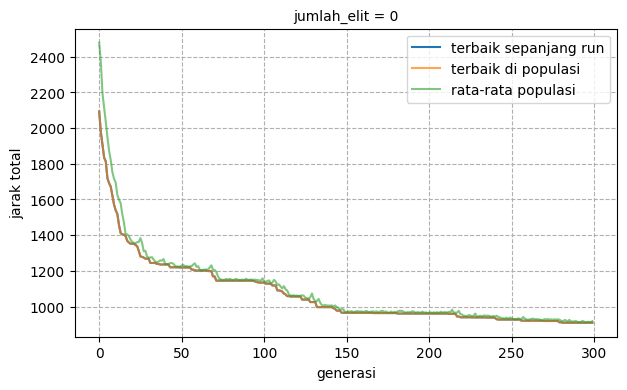

jumlah_elit = 2: jarak 951.35, waktu 2.0 detik


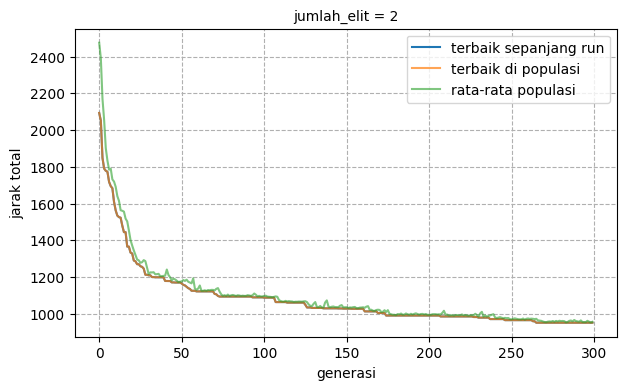

In [ ]:
for e in [0, 2]:
    hasil = genetic_algorithm_tsp_v2(jarak, jumlah_elit=e, seed=1)
    print(f"jumlah_elit = {e}: jarak {hasil['jarak']:.2f}, waktu {hasil['waktu']:.1f} detik")
    plot_konvergensi(hasil, f"jumlah_elit = {e}")

✏️ **Latihan 4.1** — Tanpa elitisme, apakah kurva "terbaik di populasi" pernah **naik** (memburuk)? Apa implikasinya terhadap proses pencarian?

✏️ **Latihan 4.2** — Dengan elitisme, kedua kurva terbaik berimpit. Informasi apa yang diberikan oleh selisih antara kurva terbaik dan kurva rata-rata mengenai keragaman populasi?

✏️ **Latihan 4.3** — Pada seed ini, versi dengan elitisme dapat berakhir **lebih buruk**. Apakah dapat disimpulkan bahwa elitisme tidak bermanfaat? Catat dugaan tersebut; fungsi `eksperimen` (beberapa seed sekaligus) digunakan mulai Tahap 5, dan elitisme diuji ulang pada Tahap 6.

## Tahap 5 — Operator lain: OX dan inversion mutation

Pada TSP, panjang rute ditentukan oleh **edge** (pasangan simpul yang bertetangga), bukan oleh posisi gen. Operator yang baik adalah operator yang mewariskan edge.

```
Order crossover OX(induk1, induk2):
1. pilih dua titik potong a <= b
2. anak[a..b] <- induk1[a..b]
3. sisanya diisi gen induk2 mulai dari posisi b+1 (memutar), lewati yang sudah ada

Inversion mutation(k):  pilih i < j, balik urutan k[i..j]     (sama dengan satu langkah 2-opt)
```
Antarmuka disamakan dengan fungsi asli: crossover menghasilkan dua anak, sedangkan mutasi menerima satu kromosom. Diharapkan bisa lebih bagus

In [ ]:
def order_crossover(induk1, induk2):                                  # BARU
    panjang_kromosom = len(induk1)
    a, b = sorted(rd.sample(range(panjang_kromosom), 2))

    def buat_anak(induk_a, induk_b):
        anak = [None] * panjang_kromosom
        anak[a:b + 1] = induk_a[a:b + 1]
        sudah_ada = set(induk_a[a:b + 1])
        urutan_b = induk_b[b + 1:] + induk_b[:b + 1]
        sisa_gen = [gen for gen in urutan_b if gen not in sudah_ada]
        posisi_kosong = list(range(b + 1, panjang_kromosom)) + list(range(0, a))
        for posisi, gen in zip(posisi_kosong, sisa_gen):
            anak[posisi] = gen
        return anak

    return buat_anak(induk1, induk2), buat_anak(induk2, induk1)

def inversion_mutation(kromosom):                                     # BARU
    i, j = sorted(rd.sample(range(len(kromosom)), 2))
    kromosom[i:j + 1] = kromosom[i:j + 1][::-1]
    return kromosom

# contoh kecil yang bisa dicek dengan tangan
rd.seed(3)
p1, p2 = [1, 2, 3, 4, 5, 6, 7, 8], [4, 8, 6, 2, 7, 1, 3, 5]
print("induk1:", p1, "\ninduk2:", p2)
print("OX            :", order_crossover(p1, p2))
print("position-based:", position_based_crossover_cepat(p1, p2))

induk1: [1, 2, 3, 4, 5, 6, 7, 8] 
induk2: [4, 8, 6, 2, 7, 1, 3, 5]
OX            : ([6, 2, 7, 4, 5, 1, 3, 8], [3, 4, 5, 2, 7, 6, 8, 1])
position-based: ([1, 6, 3, 4, 5, 2, 7, 8], [4, 1, 6, 2, 7, 3, 8, 5])


Persentase edge anak yang berasal dari salah satu induk diukur pada 2000 pasangan induk acak dengan 50 pelanggan.

In [ ]:
def himpunan_edge(kromosom):
    rute = [0] + kromosom
    return {frozenset((rute[i - 1], rute[i])) for i in range(len(rute))}

def persen_edge_warisan(anak, induk1, induk2):
    e = himpunan_edge(anak)
    return 100 * len(e & (himpunan_edge(induk1) | himpunan_edge(induk2))) / len(e)

rd.seed(5)
for nama, cx in [("position-based", position_based_crossover_cepat), ("OX", order_crossover)]:
    nilai = []
    for _ in range(2000):
        i1 = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
        i2 = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
        nilai.append(persen_edge_warisan(cx(i1, i2)[0], i1, i2))
    print(f"{nama:<15}: rata-rata {np.mean(nilai):.1f}% edge anak diwarisi dari induk")

for nama, mut in [("swap", swap_mutation), ("inversion", inversion_mutation)]:
    berubah = []
    for _ in range(2000):
        k = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
        berubah.append(len(himpunan_edge(k) - himpunan_edge(mut(k[:]))))
    print(f"mutasi {nama:<9}: rata-rata {np.mean(berubah):.2f} edge berubah (maks {max(berubah)})")

position-based : rata-rata 62.4% edge anak diwarisi dari induk
OX             : rata-rata 78.2% edge anak diwarisi dari induk
mutasi swap     : rata-rata 3.85 edge berubah (maks 4)
mutasi inversion: rata-rata 2.00 edge berubah (maks 2)


In [ ]:
kombinasi = {
    "position-based + swap": (position_based_crossover_cepat, swap_mutation),
    "position-based + inversion": (position_based_crossover_cepat, inversion_mutation),
    "OX + swap": (order_crossover, swap_mutation),
    "OX + inversion": (order_crossover, inversion_mutation),
}
print("Parameter lain sama dengan kode asli (mutation_rate 0.05), elit 2, 5 seed")
t_operator = eksperimen(jarak, {nama: dict(crossover=cx, mutasi=mut) for nama, (cx, mut) in kombinasi.items()},
                        SEEDS, jumlah_elit=2)

Parameter lain sama dengan kode asli (mutation_rate 0.05), elit 2, 5 seed
position-based + swap          rata   963.48 | terbaik   867.16 | terburuk  1046.80 | sd  64.58 | 2.0 s/run
position-based + inversion     rata   649.50 | terbaik   627.14 | terburuk   669.48 | sd  18.82 | 2.1 s/run
OX + swap                      rata   921.32 | terbaik   879.79 | terburuk   991.97 | sd  52.19 | 1.9 s/run
OX + inversion                 rata   649.97 | terbaik   609.56 | terburuk   673.34 | sd  25.56 | 1.6 s/run


✏️ **Latihan 5.1** — Kerjakan OX untuk contoh di atas secara manual. Titik potong dapat ditentukan dari keluaran program.

✏️ **Latihan 5.2** — Kaitkan hasil empat kombinasi dengan persentase edge yang diwariskan dan jumlah edge yang diubah mutasi. Jelaskan mengapa inversion lebih sesuai untuk TSP dibandingkan swap.

✏️ **Latihan 5.3** — Faktor mana yang lebih berpengaruh: pilihan crossover atau pilihan mutasi? Perhatikan pula simpangan baku, tidak hanya rata-rata.

## Tahap 6 — Rancangan eksperimen

Prinsip dari tuning ALNS berlaku pula di sini: satu eksekusi tidak cukup sebagai dasar kesimpulan. Jalankan beberapa seed, kemudian laporkan rata-rata, nilai terbaik, nilai terburuk, dan simpangan baku.

In [ ]:
OPERATOR_TERBAIK = dict(crossover=order_crossover, mutasi=inversion_mutation)

print("Laju mutasi (OX + inversion, elit 2)")
t_mutasi = eksperimen(jarak, {f"mutation_rate = {m}": dict(mutation_rate=m) for m in [0.05, 0.2, 0.5]},
                      SEEDS, jumlah_elit=2, **OPERATOR_TERBAIK)

print("\nElitisme (OX + inversion, mutation_rate 0.2)")
t_elit = eksperimen(jarak, {f"jumlah_elit = {e}": dict(jumlah_elit=e) for e in [0, 2, 20]},
                    SEEDS, mutation_rate=0.2, **OPERATOR_TERBAIK)

Laju mutasi (OX + inversion, elit 2)
mutation_rate = 0.05           rata   649.97 | terbaik   609.56 | terburuk   673.34 | sd  25.56 | 1.9 s/run
mutation_rate = 0.2            rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 2.0 s/run
mutation_rate = 0.5            rata   609.70 | terbaik   589.23 | terburuk   635.99 | sd  17.46 | 1.8 s/run

Elitisme (OX + inversion, mutation_rate 0.2)
jumlah_elit = 0                rata   597.75 | terbaik   572.89 | terburuk   619.61 | sd  20.30 | 2.4 s/run
jumlah_elit = 2                rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 2.0 s/run
jumlah_elit = 20               rata   599.88 | terbaik   590.11 | terburuk   606.94 | sd   6.63 | 1.8 s/run


✏️ **Latihan 6.1** — Tinjau kembali dugaan pada Latihan 4.3. Elitisme hampir tidak berpengaruh terhadap rata-rata; salah satu penyebabnya adalah turnamen berukuran 20 yang telah memberikan tekanan seleksi besar. Bagaimana pengaruhnya terhadap simpangan baku?

✏️ **Latihan 6.2** — Kode asli memakai `ukuran_turnamen = 10% populasi` (= 20). Uji ukuran 2, 5, dan 20 dengan fungsi `eksperimen`. Jelaskan hubungannya dengan kecepatan konvergensi dan hasil akhir. Ulangi Latihan 6.1 dengan ukuran turnamen 2.

**Anggaran yang setara.** Populasi 400 dengan 300 generasi memperoleh evaluasi dua kali lebih banyak daripada populasi 200. Perbandingan harus dilakukan pada jumlah evaluasi yang sama (ukuran_populasi × max_generation tetap).

In [ ]:
# Latihan 6.2: tulis di sini

In [ ]:
ANGGARAN = 60_000
print(f"Anggaran evaluasi sama: {ANGGARAN}")
t_pop = eksperimen(jarak, {f"populasi {m}, generasi {ANGGARAN // m}":
                           dict(ukuran_populasi=m, max_generation=ANGGARAN // m, ukuran_turnamen=max(2, m // 10))
                           for m in [50, 100, 200, 400]},
                   SEEDS, jumlah_elit=2, mutation_rate=0.2, **OPERATOR_TERBAIK)

Anggaran evaluasi sama: 60000
populasi 50, generasi 1200     rata   616.38 | terbaik   606.17 | terburuk   630.73 | sd  10.17 | 1.1 s/run
populasi 100, generasi 600     rata   602.80 | terbaik   584.50 | terburuk   625.99 | sd  17.38 | 1.6 s/run
populasi 200, generasi 300     rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 1.7 s/run
populasi 400, generasi 150     rata   613.82 | terbaik   585.66 | terburuk   635.16 | sd  21.11 | 3.1 s/run


✏️ **Latihan 6.3** — Ukuran populasi manakah yang terbaik pada anggaran ini? Jelaskan trade-off antara populasi besar (eksplorasi) dan jumlah generasi besar (eksploitasi).

## Tahap 7 — GA + 2-opt (memetic algorithm)

GA unggul dalam eksplorasi, tetapi lambat dalam memperbaiki rute secara lokal. Local search 2-opt (minggu 3) efektif untuk perbaikan lokal. Pada pendekatan ini, sebagian anak diperbaiki dengan 2-opt sebelum dimasukkan ke populasi.

```
2-opt (first improvement), simpul 0 tetap di depan:
SELAMA ada perbaikan :
   UNTUK setiap pasangan edge (a,b) dan (c,d) :
      delta <- d(a,c) + d(b,d) - d(a,b) - d(c,d)
      JIKA delta < 0 : balik segmen b..c
```

In [ ]:
def dua_opt(kromosom, jarak_list):                                    # BARU
    rute = [0] + kromosom
    n = len(rute)
    membaik = True
    while membaik:
        membaik = False
        for i in range(n - 1):
            for j in range(i + 2, n if i > 0 else n - 1):
                a, b = rute[i], rute[i + 1]
                c, d = rute[j], rute[(j + 1) % n]
                delta = jarak_list[a][c] + jarak_list[b][d] - jarak_list[a][b] - jarak_list[c][d]
                if delta < -1e-9:
                    rute[i + 1:j + 1] = rute[i + 1:j + 1][::-1]
                    membaik = True
    return rute[1:]

t_memetic = eksperimen(jarak, {"GA (OX + inversion)": dict(),
                               "GA + 2-opt pada 5% anak": dict(pemoles=dua_opt, peluang_poles=0.05)},
                       SEEDS, jumlah_elit=2, mutation_rate=0.2, **OPERATOR_TERBAIK)

GA (OX + inversion)            rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 1.8 s/run
GA + 2-opt pada 5% anak        rata   554.14 | terbaik   554.14 | terburuk   554.14 | sd   0.00 | 3.8 s/run


✏️ **Latihan 7.1** — Versi memetic memberikan hasil lebih baik, tetapi setiap pemanggilan 2-opt mengevaluasi ratusan delta sehingga jumlah evaluasi tidak lagi mencerminkan beban komputasi sebenarnya. Bagaimana perbandingan yang adil dapat dilakukan? (Petunjuk: waktu komputasi yang sama.)

✏️ **Latihan 7.2** — Gambarkan kurva konvergensi versi memetic menggunakan `plot_konvergensi`. Bagaimana perubahan selisih antara kurva terbaik dan rata-rata, dan apa risikonya?

In [ ]:
# Latihan 7.2

## Tantangan kelas — satu modifikasi sendiri (20 menit)

Rancang **satu** modifikasi GA, implementasikan, dan uji dengan fungsi `eksperimen` (3 seed, anggaran 60.000 evaluasi). Di akhir sesi, setiap mahasiswa menyampaikan modifikasinya, rata-rata jarak yang diperoleh, dan alasan modifikasi tersebut berhasil atau tidak.

Contoh di bawah adalah mutasi **or-opt**: satu segmen berisi 1–3 simpul dipindahkan ke posisi lain. Saudara boleh mengubah contoh ini atau merancang modifikasi lain, misalnya operator crossover baru atau mutasi gabungan.

Pembanding: OX + inversion, mutation_rate 0.2, elit 2.

In [ ]:
def mutasi_saya(kromosom):                                            # BARU: ubah sesuai rancangan Anda
    # contoh: or-opt, pindahkan segmen 1-3 gen ke posisi lain
    panjang_segmen = rd.randint(1, 3)
    i = rd.randrange(0, len(kromosom) - panjang_segmen + 1)
    segmen = kromosom[i:i + panjang_segmen]
    sisa = kromosom[:i] + kromosom[i + panjang_segmen:]
    j = rd.randrange(0, len(sisa) + 1)
    kromosom[:] = sisa[:j] + segmen + sisa[j:]
    return kromosom

t_tantangan = eksperimen(jarak, {"OX + inversion (pembanding)": dict(mutasi=inversion_mutation),
                                 "OX + mutasi_saya": dict(mutasi=mutasi_saya)},
                         [1, 2, 3], jumlah_elit=2, mutation_rate=0.2, crossover=order_crossover)

OX + inversion (pembanding)    rata   599.79 | terbaik   593.62 | terburuk   607.33 | sd   6.96 | 1.7 s/run
OX + mutasi_saya               rata   635.94 | terbaik   597.99 | terburuk   662.92 | sd  33.83 | 2.2 s/run


## Tahap 8 — Instance TSPLIB (persiapan Tugas GA)

Tugas memakai instance **TSPLIB** `eil51`, `berlin52`, dan `kroA100`. Berkas `.tsp` diunduh dari situs TSPLIB dan diletakkan dalam folder yang sama dengan notebook (pada Colab: unggah melalui panel Files). Jarak mengikuti aturan **EUC_2D**, yaitu dibulatkan ke bilangan bulat terdekat, agar dapat dibandingkan dengan nilai optimal. Kota pertama berperan sebagai simpul 0.

| Instance | Kota | Optimal |
|---|---|---|
| eil51 | 51 | 426 |
| berlin52 | 52 | 7542 |
| kroA100 | 100 | 21282 |

In [ ]:
import os

def baca_tsplib(path):
    koord = []
    baca = False
    with open(path) as berkas:
        for baris in berkas:
            baris = baris.strip()
            if baris.startswith("NODE_COORD_SECTION"):
                baca = True
                continue
            if baris.startswith("EOF"):
                break
            if baca and baris:
                _, x, y = baris.split()[:3]
                koord.append((float(x), float(y)))
    P = np.array(koord)
    jarak_euc = np.floor(np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(axis=-1)) + 0.5)
    return koord, jarak_euc

OPTIMAL = {"eil51": 426, "berlin52": 7542, "kroA100": 21282}
for nama, optimal in OPTIMAL.items():
    if not os.path.exists(f"{nama}.tsp"):
        print(f"{nama}.tsp belum ada, dilewati")
        continue
    koord_tsp, jarak_tsp = baca_tsplib(f"{nama}.tsp")
    hasil = genetic_algorithm_tsp_v2(jarak_tsp, jumlah_elit=2, mutation_rate=0.2, seed=1, **OPERATOR_TERBAIK)
    print(f"{nama:<9} jarak {hasil['jarak']:8.0f} | optimal {optimal:6d} | "
          f"gap {100 * (hasil['jarak'] - optimal) / optimal:5.1f}% | {hasil['waktu']:.1f} s")

eil51.tsp belum ada, dilewati
berlin52.tsp belum ada, dilewati
kroA100.tsp belum ada, dilewati


### Ringkasan
- **Pengukuran sebelum perbaikan.** Sebagian besar waktu komputasi kode asli terpusat pada satu baris crossover; penggunaan `set` mempercepatnya beberapa kali lipat tanpa mengubah algoritma.
- Untuk TSP, operator dinilai dari **edge yang diwariskan**. Pada instance ini **mutasi inversion** paling menentukan; OX sedikit lebih baik dan lebih stabil daripada position-based.
- **Elitisme** menjaga individu terbaik tetap di populasi, tetapi pengaruhnya bergantung pada tekanan seleksi; pada kasus ini hampir tidak tampak karena ukuran turnamen sudah besar.
- Bandingkan konfigurasi dengan **beberapa seed** dan **anggaran yang sama**.
- **GA + 2-opt** memberikan hasil yang jauh lebih baik, tetapi perbandingannya harus menggunakan ukuran beban komputasi yang setara.

# **Modifikasi**

Generasi    0 | Jarak Awal Terpoles = 1887.7590
Generasi    1 | Rekor Baru: 1745.7746 | Fitness = 0.000573
Generasi    2 | Rekor Baru: 1507.8182 | Fitness = 0.000663
Generasi    3 | Rekor Baru: 1330.3550 | Fitness = 0.000752
Generasi    4 | Rekor Baru: 1242.0905 | Fitness = 0.000805
Generasi    5 | Rekor Baru: 1103.2972 | Fitness = 0.000906
Generasi    6 | Rekor Baru: 956.8286 | Fitness = 0.001045
Generasi    7 | Rekor Baru: 935.6839 | Fitness = 0.001069
Generasi    8 | Rekor Baru: 788.9416 | Fitness = 0.001268
Generasi    9 | Rekor Baru: 753.1371 | Fitness = 0.001328
Generasi   10 | Rekor Baru: 641.3952 | Fitness = 0.001559
Generasi   11 | Rekor Baru: 600.4568 | Fitness = 0.001665
Generasi   12 | Rekor Baru: 558.0407 | Fitness = 0.001792
Generasi   14 | Rekor Baru: 557.9976 | Fitness = 0.001792
Generasi   16 | Rekor Baru: 554.1366 | Fitness = 0.001805

HASIL AKHIR MEMETIC ALGORITHM (PMX + ANTI-STAGNASI)
Tur Terbaik (Urutan Kunjungan) : [0, 14, 39, 34, 50, 12, 13, 35, 17, 4, 42, 28, 20

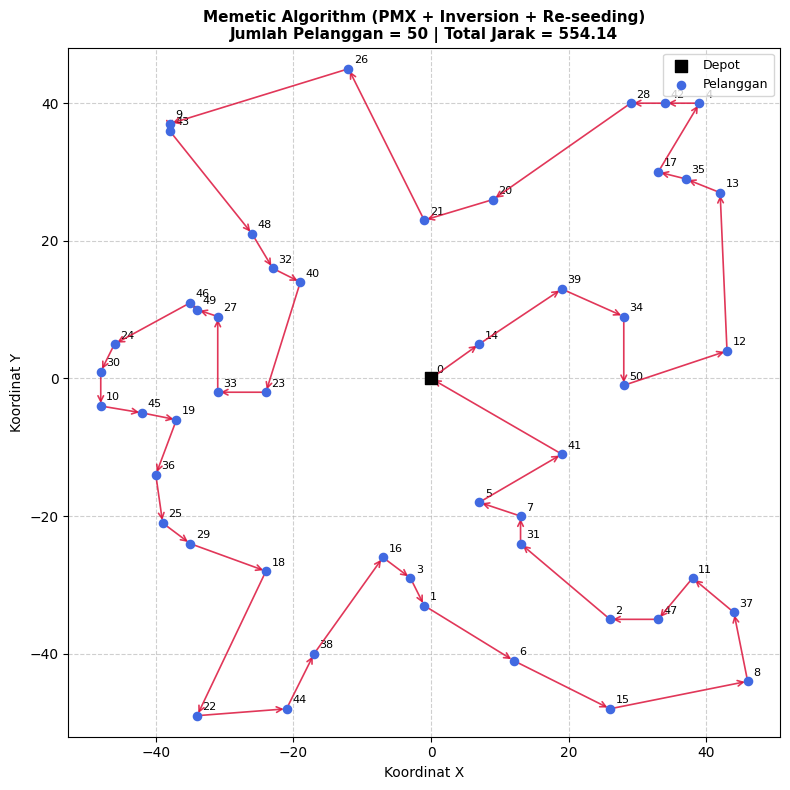

In [ ]:
# Memetic Algorithm (GA + Targeted 2-Opt) untuk TSP dengan Anti-Stagnasi
# Menggunakan PMX, Inversion Mutation, Seleksi Lembut, dan Cataclysmic Re-seeding

import time
import matplotlib.pyplot as plt
import numpy as np
import random as rd

# 1. Pembangkitan Data Koordinat & Matriks Jarak
np.random.seed(1707)  # Seed data koordinat deterministik
jumlah_pelanggan = 50
jumlah_simpul = jumlah_pelanggan + 1  # Simpul 0 adalah Depot

koord_x = [0] + [int(np.random.randint(-50, 50)) for _ in range(jumlah_simpul - 1)]
koord_y = [0] + [int(np.random.randint(-50, 50)) for _ in range(jumlah_simpul - 1)]

# Precompute matriks jarak Euclidean (Lookup O(1) list 2D Python murni)
jarak = [[0.0] * jumlah_simpul for _ in range(jumlah_simpul)]
daftar_simpul = list(range(jumlah_simpul))

for i in daftar_simpul:
    for j in daftar_simpul:
        if i != j:
            dx = koord_x[i] - koord_x[j]
            dy = koord_y[i] - koord_y[j]
            jarak[i][j] = float(np.sqrt(dx * dx + dy * dy))

np.random.seed(None)  # Nonaktifkan seed agar eksplorasi stokastik GA aktif

# 2. Parameter-Parameter Algoritma
ukuran_populasi = 200
crossover_rate = 0.90
mutation_rate = 0.3  # Peluang mutasi inversi
max_generation = 100
ukuran_turnamen = 4   # Operator 1: Mengecilkan turnamen untuk menekan homogenisasi dini
ambang_stagnan = 20   # Operator 3: Ambang batas pemicu re-seeding saat stagnan


# 3. Pembangkitan Populasi Awal
def pembangkitan_populasi_awal(ukuran_populasi):
    simpul_pelanggan = daftar_simpul[1:]  # Simpul 1 s.d. 50
    return [rd.sample(simpul_pelanggan, len(simpul_pelanggan)) for _ in range(ukuran_populasi)]


# 4. Evaluasi Fitness & Jarak Cepat
def hitung_jarak_tur(kromosom, matriks_jarak):
    d_tot = matriks_jarak[0][kromosom[0]]
    for i in range(len(kromosom) - 1):
        d_tot += matriks_jarak[kromosom[i]][kromosom[i + 1]]
    d_tot += matriks_jarak[kromosom[-1]][0]
    return d_tot


def evaluasi_populasi(populasi, matriks_jarak):
    total_jarak = [hitung_jarak_tur(k, matriks_jarak) for k in populasi]
    fitness = [1.0 / d if d > 0 else 0.0 for d in total_jarak]
    best_idx = int(np.argmax(fitness))
    return total_jarak, fitness, best_idx


# 5. Operator 1: Seleksi Turnamen Berskala Rendah
def seleksi_turnamen(populasi, fitness, k_turnamen):
    indeks_terpilih = rd.sample(range(len(populasi)), k_turnamen)
    terbaik_idx = max(indeks_terpilih, key=lambda idx: fitness[idx])
    return populasi[terbaik_idx]


# 6. Operator Crossover PMX (Goldberg & Lingle, 1985)
def partially_matched_crossover(induk1, induk2):
    n = len(induk1)
    pt1 = rd.randint(0, n - 2)
    pt2 = rd.randint(pt1 + 1, n - 1)

    def _pmx(p1, p2):
        anak = [None] * n
        anak[pt1 : pt2 + 1] = p1[pt1 : pt2 + 1]
        terpakai = set(anak[pt1 : pt2 + 1])

        pemetaan = {}
        for g1, g2 in zip(p1[pt1 : pt2 + 1], p2[pt1 : pt2 + 1]):
            pemetaan[g2] = g1

        for i in list(range(0, pt1)) + list(range(pt2 + 1, n)):
            kandidat = p2[i]
            while kandidat in pemetaan:
                kandidat = pemetaan[kandidat]
            if kandidat not in terpakai:
                anak[i] = kandidat
                terpakai.add(kandidat)

        sisa = [g for g in p2 if g not in terpakai]
        idx_sisa = 0
        for i in range(n):
            if anak[i] is None:
                anak[i] = sisa[idx_sisa]
                idx_sisa += 1
        return anak

    return _pmx(induk1, induk2), _pmx(induk2, induk1)


# 7. Operator 2: Mutasi Inversi (Inversion / 2-Opt Mutation)
def inversion_mutation(kromosom):
    """Membalik urutan segmen acak [i..j], meloloskan dari perangkap tanpa merusak struktur tur."""
    n = len(kromosom)
    idx1, idx2 = sorted(rd.sample(range(n), 2))
    kromosom[idx1 : idx2 + 1] = reversed(kromosom[idx1 : idx2 + 1])
    return kromosom


# 8. Komponen Memetic: 2-Opt Local Search (First-Improvement Delta Cepat)
def local_search_2opt(kromosom, matriks_jarak, max_iter=30):
    tur = [0] + list(kromosom) + [0]
    n_tur = len(tur)
    ada_perbaikan = True
    iter_count = 0

    while ada_perbaikan and iter_count < max_iter:
        ada_perbaikan = False
        iter_count += 1
        for i in range(1, n_tur - 2):
            u1, v1 = tur[i - 1], tur[i]
            for j in range(i + 1, n_tur - 1):
                u2, v2 = tur[j], tur[j + 1]
                selisih = (
                    matriks_jarak[u1][u2]
                    + matriks_jarak[v1][v2]
                    - matriks_jarak[u1][v1]
                    - matriks_jarak[u2][v2]
                )
                if selisih < -1e-6:
                    tur[i : j + 1] = reversed(tur[i : j + 1])
                    ada_perbaikan = True
                    break
            if ada_perbaikan:
                break

    return tur[1:-1]


# 9. Reproduksi Memetic (Crossover PMX + Mutasi Inversi + 2-Opt pada Anak)
def reproduksi(ukuran_populasi, populasi, fitness, cr, mr, k_turnamen, matriks_jarak):
    populasi_baru = []
    for _ in range(ukuran_populasi // 2):
        induk1 = seleksi_turnamen(populasi, fitness, k_turnamen)
        induk2 = seleksi_turnamen(populasi, fitness, k_turnamen)

        # Crossover PMX
        if rd.random() < cr:
            anak1, anak2 = partially_matched_crossover(induk1, induk2)
        else:
            anak1, anak2 = list(induk1), list(induk2)

        # Mutasi Inversi
        if rd.random() < mr:
            anak1 = inversion_mutation(anak1)
        if rd.random() < mr:
            anak2 = inversion_mutation(anak2)

        # INTI MEMETIC: Poles anak baru dengan 2-Opt ringan (max 10 swap)
        # Langkah ini memastikan seluruh populasi berkembang bersama, bukan cuma 1 individu!
        anak1 = local_search_2opt(anak1, matriks_jarak, max_iter=10)
        anak2 = local_search_2opt(anak2, matriks_jarak, max_iter=10)

        populasi_baru.extend([anak1, anak2])
    return populasi_baru


# 10. Algoritma Utama: Memetic Algorithm TSP
def memetic_algorithm_tsp(
    matriks_jarak,
    ukuran_populasi=100,  # Ukuran 100 sudah sangat cukup dan jauh lebih cepat
    cr=0.85,
    mr=0.20,
    max_gen=150,          # 150 generasi sudah konvergen sangat tajam
    k_turnamen=3,         # Turnamen kecil agar populasi tetap beragam
):
    # Inisialisasi populasi awal (langsung poles 2-opt agar start sudah bagus)
    populasi_mentah = pembangkitan_populasi_awal(ukuran_populasi)
    populasi = [local_search_2opt(k, matriks_jarak, max_iter=15) for k in populasi_mentah]

    total_jarak, fitness, p_best = evaluasi_populasi(populasi, matriks_jarak)
    best_kromosom = list(populasi[p_best])
    best_cost = total_jarak[p_best]
    riwayat_jarak = [best_cost]

    print(f"Generasi    0 | Jarak Awal Terpoles = {best_cost:.4f}")

    for gen in range(1, max_gen + 1):
        # 1. Reproduksi memetic (setiap anak langsung dipoles 2-opt)
        populasi_baru = reproduksi(ukuran_populasi, populasi, fitness, cr, mr, k_turnamen, matriks_jarak)

        # 2. Elitisme: Pertahankan rekor terbaik
        populasi_baru[0] = list(best_kromosom)
        populasi = populasi_baru

        # 3. Evaluasi Populasi Baru
        total_jarak, fitness, p_best = evaluasi_populasi(populasi, matriks_jarak)

        # 4. Update Rekor Global
        if total_jarak[p_best] < best_cost:
            best_cost = total_jarak[p_best]
            best_kromosom = list(populasi[p_best])
            print(f"Generasi {gen:>4} | Rekor Baru: {best_cost:.4f} | Fitness = {1.0 / best_cost:.6f}")

        riwayat_jarak.append(best_cost)

    best_solusi = [0] + best_kromosom + [0]
    return best_solusi, best_cost, riwayat_jarak


# Eksekusi Program
saat_mulai = time.time()
best_solusi, best_cost, riwayat = memetic_algorithm_tsp(
    matriks_jarak=jarak,
    ukuran_populasi=ukuran_populasi,
    cr=crossover_rate,
    mr=mutation_rate,
    max_gen=max_generation,
    k_turnamen=ukuran_turnamen
)
waktu_komputasi = time.time() - saat_mulai

print("\n" + "=" * 55)
print("HASIL AKHIR MEMETIC ALGORITHM (PMX + ANTI-STAGNASI)")
print("=" * 55)
print(f"Tur Terbaik (Urutan Kunjungan) : {best_solusi}")
print(f"Total Jarak Solusi             : {best_cost:.4f}")
print(f"Waktu Komputasi                : {waktu_komputasi:.2f} detik")

# Visualisasi Solusi Geografis (Plot Rute TSP)
plt.figure(figsize=(8, 8))
plt.scatter(koord_x[0], koord_y[0], marker='s', color='black', s=80, label='Depot', zorder=5)
plt.scatter(koord_x[1:], koord_y[1:], marker='o', color='royalblue', s=35, label='Pelanggan', zorder=4)

for i in daftar_simpul:
    plt.text(koord_x[i] + 0.8, koord_y[i] + 0.8, str(i), fontsize=8)

for i in range(len(best_solusi) - 1):
    curr_n = best_solusi[i]
    next_n = best_solusi[i + 1]
    plt.annotate(
        "",
        xy=(koord_x[next_n], koord_y[next_n]),
        xytext=(koord_x[curr_n], koord_y[curr_n]),
        arrowprops=dict(arrowstyle="->", color="crimson", lw=1.2, alpha=0.85),
    )

plt.title(
    f"Memetic Algorithm (PMX + Inversion + Re-seeding)\nJumlah Pelanggan = {jumlah_pelanggan} | Total Jarak = {best_cost:.2f}",
    fontsize=11,
    fontweight="bold",
)
plt.xlabel("Koordinat X")
plt.ylabel("Koordinat Y")
plt.grid(True, linestyle="--", alpha=0.6)
plt.axis("equal")
plt.legend(fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
def mutasi_kombinasi_saya(kromosom):
    # BARU: Menggabungkan Inversion dan Scramble Mutation secara acak
    if rd.random() < 0.5:
        # Inversion Mutation
        i, j = sorted(rd.sample(range(len(kromosom)), 2))
        kromosom[i:j + 1] = kromosom[i:j + 1][::-1]
    else:
        # Scramble Mutation (mengacak sub-segmen kecil sepanjang 2-4)
        panjang = rd.randint(2, 4)
        i = rd.randint(0, len(kromosom) - panjang)
        sub_segmen = kromosom[i:i + panjang]
        rd.shuffle(sub_segmen)
        kromosom[i:i + panjang] = sub_segmen
    return kromosom

# Perbaikan: Kembalikan fungsi seleksi_turnamen asli yang menerima 4 parameter
def seleksi_turnamen(ukuran_populasi, x_populasi, nilai_fitness, ukuran_turnamen):
    indeks_parent_terpilih = rd.sample(range(ukuran_populasi), ukuran_turnamen)
    kandidat = [(x_populasi[i], nilai_fitness[i]) for i in indeks_parent_terpilih]
    kandidat.sort(key=lambda x: x[1], reverse=True)
    parent = kandidat[0][0]
    return parent

# Menjalankan eksperimen dengan anggaran 60.000 evaluasi (3 seeds)
ANGGARAN_EVALUASI = 60000
ukuran_pop_uji = 200
generasi_uji = ANGGARAN_EVALUASI // ukuran_pop_uji  # 300 generasi

konfigurasi_tantangan = {
    "OX + Inversion (Pembanding)": dict(
        ukuran_populasi=ukuran_pop_uji,
        max_generation=generasi_uji,
        mutasi=inversion_mutation,
        crossover=order_crossover
    ),
    "OX + Mutasi Kombinasi Saya": dict(
        ukuran_populasi=ukuran_pop_uji,
        max_generation=generasi_uji,
        mutasi=mutasi_kombinasi_saya,
        crossover=order_crossover
    )
}

print(f"Eksperimen Tantangan Kelas (Budget: {ANGGARAN_EVALUASI} Evaluasi, 3 Seeds):")
t_tantangan_baru = eksperimen(
    jarak,
    konfigurasi_tantangan,
    seeds=[1, 2, 3],
    jumlah_elit=2,
    mutation_rate=0.2
)

Eksperimen Tantangan Kelas (Budget: 60000 Evaluasi, 3 Seeds):
OX + Inversion (Pembanding)    rata   599.79 | terbaik   593.62 | terburuk   607.33 | sd   6.96 | 2.1 s/run
OX + Mutasi Kombinasi Saya     rata   612.99 | terbaik   582.49 | terburuk   647.40 | sd  32.63 | 1.6 s/run
